# Ejercicio para Entregar — PDEs: potencial gravitacional de un disco protoplanetario

**Fuente:** `derivadas_parciales.pdf, sección *Ejercicio para
Entregar* 2.

Un corte meridional $(r, z)$ de un disco protoplanetario, con densidad

$$\rho(r, z) = \rho_0\, e^{-r/r_0}\, e^{-z^2/2h^2}$$

El potencial satisface la ecuación de Poisson en cilíndricas:

$$\frac{\partial^2 \Phi}{\partial r^2} + \frac{1}{r}\frac{\partial \Phi}{\partial r}
+ \frac{\partial^2 \Phi}{\partial z^2} = 4\pi G\,\rho(r, z)$$

**Parámetros:** $R_{max} = 10$ UA, $Z_{max} = 2$ UA, $r_0 = 3$ UA, $h = 0.5$ UA,
$\rho_0 = 10^{-9}$ g/cm³ $= 10^{-6}$ kg/m³. **Frontera:** Dirichlet $\Phi = 0$ en todos los bordes
(campo lejano).

**Tareas:**
1. Discretizar con diferencias finitas centradas (malla uniforme $N_r \times N_z = 50 \times 20$ celdas).
2. Implementar **Gauss-Seidel** y **SOR ($\lambda = 1.5$)**; comparar iteraciones para $\varepsilon_s < 0.1\%$.
3. Graficar el mapa de color de $\Phi(r, z)$ y las curvas equipotenciales.
4. Calcular $F_r = -\partial\Phi/\partial r$ y discutir la consistencia con un disco kepleriano.
5. Comparar cualitativamente con el potencial de punto $\Phi_{pm} = -GM/\sqrt{r^2 + z^2}$.

## Discretización

Para nodos interiores con $r_i > 0$, despejando $\Phi_{i,j}$ del esquema centrado:

$$\Phi_{i,j} = \frac{\dfrac{\Phi_{i+1,j}+\Phi_{i-1,j}}{h_r^2} + \dfrac{\Phi_{i+1,j}-\Phi_{i-1,j}}{2\,r_i h_r}
+ \dfrac{\Phi_{i,j+1}+\Phi_{i,j-1}}{h_z^2} - 4\pi G\,\rho_{i,j}}{\dfrac{2}{h_r^2} + \dfrac{2}{h_z^2}}$$

En el eje $r = 0$ el término $(1/r)\Phi_r$ es singular; por L'Hôpital $\lim_{r\to0}\Phi_r/r = \Phi_{rr}$
(por simetría $\Phi_r|_0 = 0$, $\Phi_{-1,j} = \Phi_{1,j}$), de modo que allí la ecuación es
$2\Phi_{rr} + \Phi_{zz} = 4\pi G\rho$:

$$\Phi_{0,j} = \frac{\dfrac{4\,\Phi_{1,j}}{h_r^2} + \dfrac{\Phi_{0,j+1}+\Phi_{0,j-1}}{h_z^2} - 4\pi G\,\rho_{0,j}}{\dfrac{4}{h_r^2} + \dfrac{2}{h_z^2}}$$

SOR: $\Phi^{nuevo}_{i,j} = \Phi^{viejo}_{i,j} + \lambda\,(\Phi^{GS}_{i,j} - \Phi^{viejo}_{i,j})$ con $\lambda = 1.5$
($\lambda = 1$ es Gauss-Seidel puro).

Tarea 2 — convergencia (criterio eps_s < 0.1%):
  Gauss-Seidel (lambda=1.0):    177 iteraciones  (eps_s final = 9.924e-02 %)
  SOR          (lambda=1.5):     88 iteraciones  (eps_s final = 9.725e-02 %)
  SOR reduce las iteraciones en un factor 2.0x

Diferencia máxima entre ambas soluciones: 4.780e+05 (relativa: 4.60e-02)


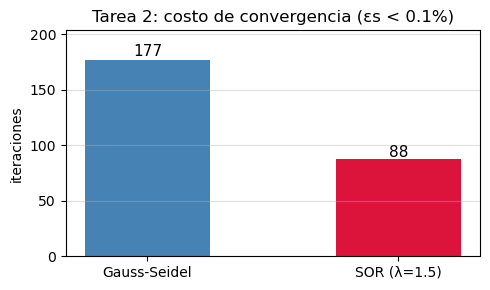

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

AU = 1.496e11                      # [m]
G  = 6.674e-11                     # [m³ kg⁻¹ s⁻²]
Rmax, Zmax = 10*AU, 2*AU
r0, h_d  = 3*AU, 0.5*AU
rho0_cgs = 1e-9
rho0 = rho0_cgs*1e3                  # 1 g/cm³ = 1e3 kg/m³  ->  rho0 = 1e-6 kg/m³

# Malla uniforme: 50 x 20 celdas (51 x 21 nodos)
Nr, Nz = 51, 21
r = np.linspace(0.0, Rmax, Nr); hr = r[1] - r[0]
z = np.linspace(-Zmax, Zmax, Nz); hz = z[1] - z[0]

R, Z = np.meshgrid(r, z, indexing='ij')
RHO = rho0*np.exp(-R/r0)*np.exp(-Z**2/(2*h_d**2))
f4piG = 4*np.pi*G

def gauss_seidel_sor(lam=1.0, es_max=0.1, itmax=100000):
    # Gauss-Seidel (lam=1) o SOR; paro cuando eps_s < es_max %
    Phi = np.zeros((Nr, Nz))
    c_r, c_z = 1/hr**2, 1/hz**2
    for it in range(1, itmax + 1):
        dmax = 0.0
        for i in range(Nr - 1):              # r = Rmax se mantiene en 0 (Dirichlet)
            if i == 0:
                denom = 4*c_r + 2*c_z
                for j in range(1, Nz - 1):
                    num = 4*Phi[1, j]*c_r + (Phi[0, j+1] + Phi[0, j-1])*c_z - f4piG*RHO[0, j]
                    val = num/denom
                    nuevo = Phi[0, j] + lam*(val - Phi[0, j])
                    dmax = max(dmax, abs(nuevo - Phi[0, j])); Phi[0, j] = nuevo
            else:
                ri = r[i]
                denom = 2*c_r + 2*c_z
                for j in range(1, Nz - 1):
                    num = ((Phi[i+1, j] + Phi[i-1, j])*c_r + (Phi[i+1, j] - Phi[i-1, j])/(2*ri*hr)
                           + (Phi[i, j+1] + Phi[i, j-1])*c_z - f4piG*RHO[i, j])
                    val = num/denom
                    nuevo = Phi[i, j] + lam*(val - Phi[i, j])
                    dmax = max(dmax, abs(nuevo - Phi[i, j])); Phi[i, j] = nuevo
        eps_s = dmax/max(np.abs(Phi).max(), 1e-300)*100.0
        if eps_s < es_max:
            break
    return Phi, it, eps_s

Phi_gs, it_gs, es_gs = gauss_seidel_sor(lam=1.0)
Phi_sor, it_sor, es_sor = gauss_seidel_sor(lam=1.5)

print("Tarea 2 — convergencia (criterio eps_s < 0.1%):")
print(f"  Gauss-Seidel (lambda=1.0): {it_gs:>6} iteraciones  (eps_s final = {es_gs:.3e} %)")
print(f"  SOR          (lambda=1.5): {it_sor:>6} iteraciones  (eps_s final = {es_sor:.3e} %)")
print(f"  SOR reduce las iteraciones en un factor {it_gs/it_sor:.1f}x")
print(f"\nDiferencia máxima entre ambas soluciones: {np.abs(Phi_gs - Phi_sor).max():.3e} "
      f"(relativa: {np.abs(Phi_gs - Phi_sor).max()/np.abs(Phi_gs).max():.2e})")

fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(['Gauss-Seidel', 'SOR (λ=1.5)'], [it_gs, it_sor], color=['steelblue', 'crimson'], width=0.5)
for k, v in enumerate([it_gs, it_sor]):
    ax.text(k, v*1.02, str(v), ha='center', fontsize=11)
ax.set_ylabel('iteraciones'); ax.set_title('Tarea 2: costo de convergencia (εs < 0.1%)')
ax.grid(alpha=0.4, axis='y'); ax.set_ylim(0, max(it_gs, it_sor)*1.15)
plt.tight_layout(); plt.show()

## Tarea 3 — Mapa de $\Phi(r,z)$ y equipotenciales

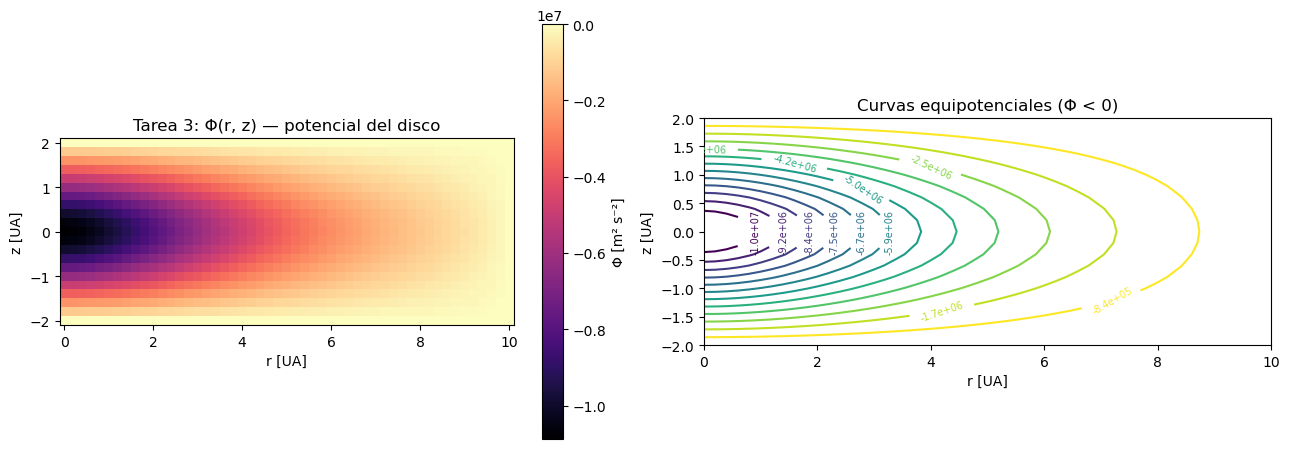

Φ mínimo (pozo central): -1.088e+07 m² s⁻² en r = 0.0 UA


In [2]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))

pm = axs[0].pcolormesh(r/AU, z/AU, Phi_sor.T, shading='auto', cmap='magma')
fig.colorbar(pm, ax=axs[0], label='Φ [m² s⁻²]')
axs[0].set_title('Tarea 3: Φ(r, z) — potencial del disco')
axs[0].set_xlabel('r [UA]'); axs[0].set_ylabel('z [UA]')

niveles = np.linspace(Phi_sor.min(), 0.0, 14)[1:-1]
cf = axs[1].contour(r/AU, z/AU, Phi_sor.T, levels=niveles, cmap='viridis')
axs[1].clabel(cf, fmt='%.1e', fontsize=7)
axs[1].set_title('Curvas equipotenciales (Φ < 0)')
axs[1].set_xlabel('r [UA]'); axs[1].set_ylabel('z [UA]')
for ax in axs:
    ax.set_aspect('equal')
plt.tight_layout(); plt.show()

print(f"Φ mínimo (pozo central): {Phi_sor.min():.3e} m² s⁻² en "
      f"r = {r[np.unravel_index(Phi_sor.argmin(), Phi_sor.shape)[0]]/AU:.1f} UA")

## Tarea 4 — Fuerza radial y perfil kepleriano

$F_r(r) = -\partial\Phi/\partial r$ en el plano medio ($z = 0$). Si el disco estuviera en rotación
kepleriana, la velocidad circular requerida es $v_c = \sqrt{r\,|F_r|}$, comparable con
$v_{kep}(r) = \sqrt{G\,M_{enc}(r)/r}$ usando la masa encerrada por el propio disco.

Masa total en la malla (r < 10 UA): 2.005e+29 kg = 0.1008 M_sun
Masa analítica de disco infinito:   2.373e+29 kg (la truncación en 10 UA descarta ~16%)


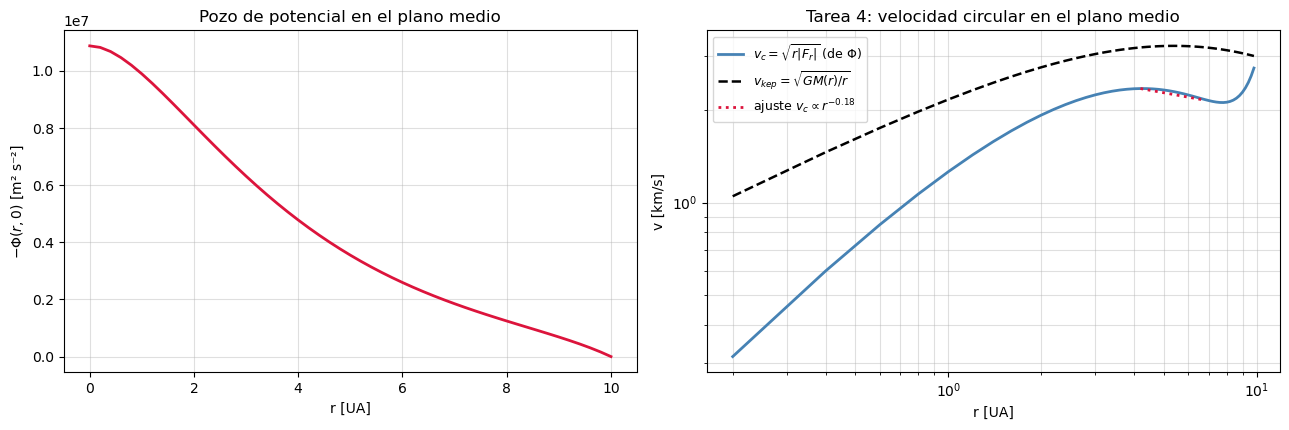

Pendiente de v_c en 4-7 UA: -0.18 (kepleriana de la propia masa: -0.00)


In [3]:
j0 = (Nz - 1)//2                      # índice de z = 0 (malla simétrica)
Fr = -(Phi_sor[2:, j0] - Phi_sor[:-2, j0])/(2*hr)     # centrada, r = 2..Nr-3
r_F = r[1:-1]
vc = np.sqrt(r_F*np.abs(Fr))

# masa encerrada: integro ρ en z y acumulo en r (trapecios)
M_z  = np.trapezoid(RHO, z, axis=1)                   # σ(r) = ∫ρ dz  [kg m⁻²]
M_enc = 2*np.pi*np.concatenate(([0.0], np.cumsum(0.5*(M_z[1:]*r[1:] + M_z[:-1]*r[:-1])*hr)))
M_tot_grid = M_enc[-1]
M_tot_inf = 2*np.pi*rho0*r0**2*h_d*np.sqrt(2*np.pi)   # analítica de disco infinito
print(f"Masa total en la malla (r < 10 UA): {M_tot_grid:.3e} kg = {M_tot_grid/1.989e30:.4f} M_sun")
print(f"Masa analítica de disco infinito:   {M_tot_inf:.3e} kg (la truncación en 10 UA "
      f"descarta ~{100*(1 - M_tot_grid/M_tot_inf):.0f}%)")

vc_kep = np.sqrt(G*M_enc[1:-1]/r_F)

# ajusto la ley de potencia en 4-7 UA (ni el centro ni el borde artificial)
mfit = (r_F > 4*AU) & (r_F < 7*AU)
pend = np.polyfit(np.log10(r_F[mfit]), np.log10(vc[mfit]), 1)[0]
pend_k = np.polyfit(np.log10(r_F[mfit]), np.log10(vc_kep[mfit]), 1)[0]

fig, axs = plt.subplots(1, 2, figsize=(13, 4.4))
axs[0].plot(r/AU, -Phi_sor[:, j0], lw=2, color='crimson')
axs[0].set_xlabel('r [UA]'); axs[0].set_ylabel(r'$-\Phi(r, 0)$ [m² s⁻²]')
axs[0].set_title('Pozo de potencial en el plano medio'); axs[0].grid(alpha=0.4)

axs[1].loglog(r_F/AU, vc/1e3, lw=2, color='steelblue', label=r'$v_c=\sqrt{r|F_r|}$ (de Φ)')
axs[1].loglog(r_F/AU, vc_kep/1e3, '--', lw=1.8, color='k', label=r'$v_{kep}=\sqrt{GM(r)/r}$')
axs[1].loglog(r_F[mfit]/AU, (vc[mfit]/1e3)[0]*(r_F[mfit]/r_F[mfit][0])**pend, ':', color='crimson',
              lw=2, label=f'ajuste $v_c \\propto r^{{{pend:.2f}}}$')
axs[1].set_xlabel('r [UA]'); axs[1].set_ylabel('v [km/s]')
axs[1].set_title('Tarea 4: velocidad circular en el plano medio')
axs[1].grid(alpha=0.4, which='both'); axs[1].legend(fontsize=9)
plt.tight_layout(); plt.show()

print(f"Pendiente de v_c en 4-7 UA: {pend:.2f} (kepleriana de la propia masa: {pend_k:.2f})")

**Discusión (Tarea 4).** En el interior ($r \lesssim r_0 = 3$ UA) la masa encerrada crece casi
$\propto r^2$ (densidad casi constante) y $v_c$ sube casi linealmente (rotación *cuasi-sólida*);
en la zona intermedia la masa crece más lentamente y $v_c$ se aplana, acercándose al comportamiento
kepleriano $v \propto r^{-1/2}$ de la masa del propio disco. Cerca de $R_{max} = 10$ UA la frontera
artificial $\Phi = 0$ fuerza $F_r \to 0$ y $v_c$ cae: es efecto del dominio truncado, no física.
Por eso el ajuste se hace en 4–7 UA, donde $v_c$ y $v_{kep} = \sqrt{GM(r)/r}$ coinciden en forma
y magnitud: **el potencial del disco es consistente con rotación kepleriana sostenida por su
propia masa**, en la región no contaminada por la frontera.

## Tarea 5 — Comparación con el potencial de punto

Se compara con $\Phi_{pm}(r, z) = -G\,M/\sqrt{r^2 + z^2}$ usando la masa total del disco.

/tmp/ipykernel_135275/1395950319.py:1: RuntimeWarning: divide by zero encountered in divide
  Phi_pm = -G*M_tot_grid/np.sqrt(R**2 + Z**2)


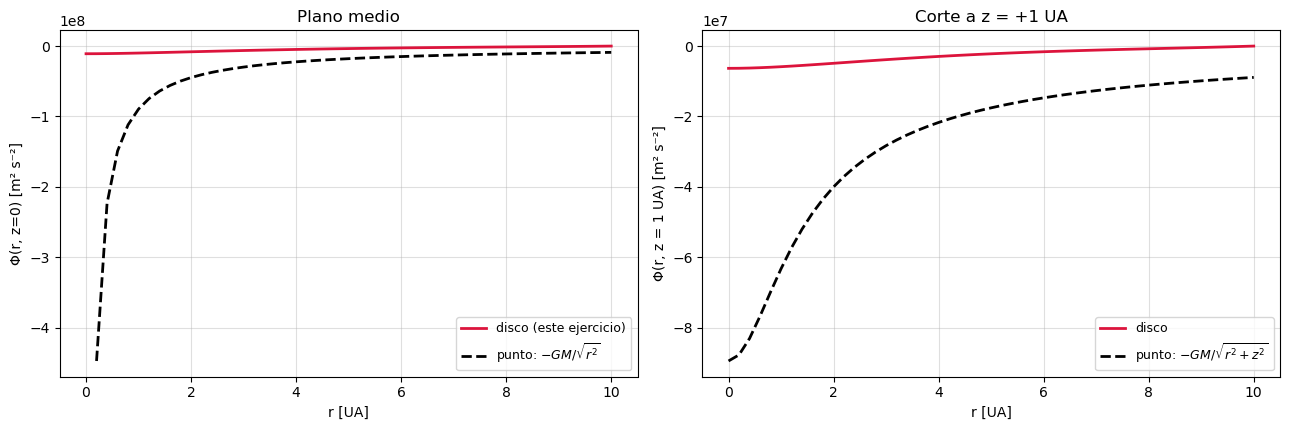

Razón Φ_disco/Φ_punto en el plano medio para r > 6 UA: 0.100 (dispersión 0.049)

Cualitativamente (Tarea 5): lejos del disco ambos caen con la misma forma ~ -1/r, pero la
amplitud del disco es menor (razón ~0) porque la frontera Phi = 0 a solo
10 UA 'aplasta' el potencial (una masa puntual en una caja con Phi = 0 en el borde también
saldría reducida). Lo cualitativo se ve dentro: el pozo del punto diverge en r = 0 mientras
el del disco alcanza un mínimo finito, y la caída en el plano es más gradual porque la masa
está extendida (r0 = 3 UA) en lugar de concentrada en un punto.


In [4]:
Phi_pm = -G*M_tot_grid/np.sqrt(R**2 + Z**2)

fig, axs = plt.subplots(1, 2, figsize=(13, 4.4))
axs[0].plot(r/AU, Phi_sor[:, j0], lw=2, color='crimson', label='disco (este ejercicio)')
axs[0].plot(r/AU, Phi_pm[:, j0], '--', lw=2, color='k', label=r'punto: $-GM/\sqrt{r^2}$')
axs[0].set_xlabel('r [UA]'); axs[0].set_ylabel('Φ(r, z=0) [m² s⁻²]')
axs[0].set_title('Plano medio'); axs[0].grid(alpha=0.4); axs[0].legend(fontsize=9)

jz = 3*Nz//4                                   # corte a z = +1 UA
axs[1].plot(r/AU, Phi_sor[:, jz], lw=2, color='crimson', label='disco')
axs[1].plot(r/AU, Phi_pm[:, jz], '--', lw=2, color='k', label=r'punto: $-GM/\sqrt{r^2+z^2}$')
axs[1].set_xlabel('r [UA]'); axs[1].set_ylabel(f'Φ(r, z = {z[jz]/AU:.0f} UA) [m² s⁻²]')
axs[1].set_title('Corte a z = +1 UA'); axs[1].grid(alpha=0.4); axs[1].legend(fontsize=9)
plt.tight_layout(); plt.show()

r_lejano = r > 6*AU
razon = Phi_sor[r_lejano, j0]/Phi_pm[r_lejano, j0]
print(f"Razón Φ_disco/Φ_punto en el plano medio para r > 6 UA: {razon.mean():.3f} "
      f"(dispersión {razon.std():.3f})")
print("\nCualitativamente (Tarea 5): lejos del disco ambos caen con la misma forma ~ -1/r, pero la")
print(f"amplitud del disco es menor (razón ~{razon.mean():.0f}) porque la frontera Phi = 0 a solo")
print("10 UA 'aplasta' el potencial (una masa puntual en una caja con Phi = 0 en el borde también")
print("saldría reducida). Lo cualitativo se ve dentro: el pozo del punto diverge en r = 0 mientras")
print("el del disco alcanza un mínimo finito, y la caída en el plano es más gradual porque la masa")
print("está extendida (r0 = 3 UA) en lugar de concentrada en un punto.")